# 调试快捷键

| 快捷键         | 功能       | 作用                     |
| -------------- | ---------- | ------------------------ |
| F5             | Continue   | 继续运行，直到下一个断点 |
| F10            | Step Over  | 单步跳过，不进入函数内部 |
| F11            | Step Into  | 单步进入函数内部         |
| Shift + F11    | Step Out   | 跳出当前函数             |
| Ctrl + Shift + F5 | Restart  | 重新启动整个调试程序     |
| Shift + F5     | Stop       | 停止调试                 |

# 调试中的launch.json配置文件

## *1.* module and program ：

在 VS Code 的 launch.json 中，module 和 program 都是用来指定 Python 调试入口的，但它们指定入口的方式不同。
- program：通过 Python 文件的路径运行程序。
- module：通过 Python 模块的名称运行程序。\
例如：
```python
 "program": "${workspaceFolder}/navsim/planning/script/run_create_submission_pickle.py"
```
其中："${workspaceFolder}"代表VS Code 当前打开的项目根目录。
```python
"module": "navsim.planning.script.run_create_submission_pickle"
```
**要想直接调试当前文件，不特定文件名称/路径：**
```python
"program": "${file}",
```

## *2.* launch.json特点：

VSCode 的 Python 调试器是单独拉起进程，不会复用你手动在终端里 $export$的变量，必须在 $launch.json$ 里显式注入。
**{export语法在py文件进行调试的时候不起作用}**\
解决办法:
- 在json文件中怎加$env$变量：
```python
"env": {
        "OPENSCENE_DATA_ROOT": "/mnt/g/Udata/openscene-v1.1"
}
```

**对于上述问题的处理：**\
例如，在 Ubuntu 终端中设置：
```python
export NODE_RANK=2
```
那么 Python 中采用如下的操作就能够解决上述状况：
```python
import os
print(os.environ.get("NODE_RANK"))
```
***os.environ 用来访问操作系统中的环境变量。***\
*注意:*
os.environ.get("NODE_RANK", 0)
它有两个参数：get(变量名, 默认值)
- "NODE_RANK"：要查找的环境变量名称。
- 0：如果环境变量不存在，就返回默认值 0

# 调试相关操作

## 1.breakpoints

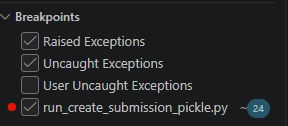
- Raised Exceptions（已引发的异常）**可以取消勾选：正常捕获的异常不会频繁打断你。**
  - 当 Python 代码抛出异常时就暂停，即使这个异常后来被 try-except 捕获也可能暂停。
- Uncaught Exceptions（未捕获的异常）**建议保留：真正没有被捕获、导致程序崩溃的异常，仍然会暂停并提示你**
  - 当异常没有被程序捕获，最终向外传播时，调试器暂停。
- User Uncaught Exceptions（用户代码中的未捕获异常）
  - 主要用于限制异常断点的范围，只关注用户代码中未捕获的异常，而不是调试器所涉及的所有库代码中的异常。
- run_create_submission_pickle.py
  - 红色圆点：表示设置了断点。
  - 左边勾选框：表示这个断点当前处于启用状态。
  - 右边蓝色的 24：表示断点位于第 24 行。\
**注意：取消勾选只是暂时禁用断点，不会删除断点。**

## 2.Variables（变量查看器）

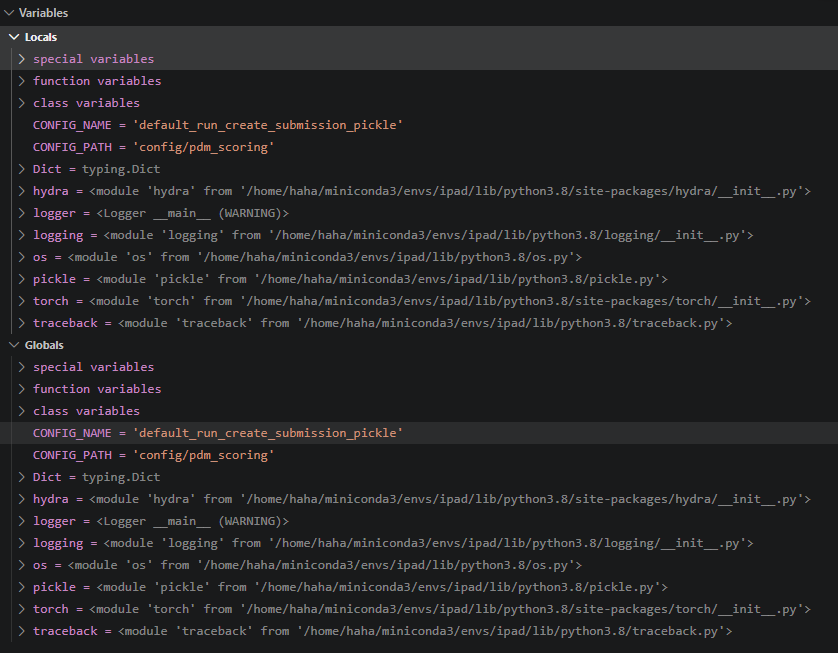
- Locals（局部变量）：指当前函数或代码执行作用域中的局部变量。
- Globals（全局变量）：指当前 Python 模块的全局命名空间中的变量。
- **上面局部和全局变量一样,是因为：** 因为你现在很停留在 Python 文件的模块级作用域，还没有进入 main() 函数。在模块级作用域中，局部命名空间和全局命名空间实际上是同一个命名空间。进入函数后，两者就会有明显区别。

## 3.Watch（监视）

- 作用：**自定义监控你关心的变量 / 表达式**，不是自动列出全部变量，只看你加进去的东西Microsoft ...
- 例子：你可以写 `a + b`、`loss.item()`，或者某个你重点盯的变量，每暂停一次就自动刷新值
- 和 Variables 区别：Variables 是当前作用域所有变量；Watch 是**你自己挑选、长期盯着**的表达式，跨步骤持续观察

## 4.Call Stack（调用栈）

- 作用：**函数调用链路，记录代码是怎么一步步跑到当前这一行的**
- 栈顶 = 当前正在执行的函数；下面一层一层，是谁调用了谁
- 用法：点击栈里任意一行，可以切回上一层函数，看当时的变量；找报错、递归、多层嵌套函数的时候超级好用，用来溯源代码执行路径

# 数据块

## 1.数据块的特点：

数据块当你打断点进行调试的时候是不会在断点处停留的，也就是无法进行调试；**所以解决办法就是：用他的激活函数去调用它，来实现对他的调试**\
**怎样找到都有谁调用过这个数据块：**
```python
grep -RnE "from navsim.common.dataloader import|import navsim.common.dataloader" /home/haha/iPad-main --include="*.py"
```
参数解释：
| 参数 | 含义 |
| ---- | ---- |
| grep | 文本搜索工具 |
| -R | 递归搜索所有子目录 |
| -n | 显示匹配内容所在行号 |
| -E | 支持扩展正则表达式 |
| --include="*.py" | 只搜索 Python 文件 |
